# Shadow weights in a fully connected network: 2-task multi-MNIST

Do shadow weights alone train the hidden units, or does each unit still need gradients from the other outputs? And do
shadow weights fix how the hidden units are split between the tasks?

Fully connected, our method never mixes the tasks, but it splits the hidden units unevenly between them early on and
never revises the split, which leaves it 5.0 points below the ideal connectivity (allocation 0.63,
`multi_mnist.ipynb`). Shadow weights give every hidden unit a gradient from one randomly chosen output from the
start, so each task gets about as many units learning its features as it has outputs: 10 ± 2 units per task (expected
allocation 0.82). They exploit the fact that here the units should be split in proportion to the outputs, so they are
kept apart from the main line of experiments, which looks for a learner that finds the split itself.

**Shadow weights.** Each hidden unit is paired with an output drawn at random (so a task can get more or fewer than 10
units), and that connection gets a fixed shadow weight of $+1$ or $-1$, also drawn at random, used only in the backward
pass. The forward pass is unchanged and the output weights keep their true gradients. Two versions:
- *shadow weights*: a unit's gradient comes from every output through the output weights, as in backprop, except that
  the weight from its paired output counts as its shadow weight unless the real one is larger in magnitude.
- *shadow weights only*: a unit's gradient comes only from its paired output, through its shadow weight.

**Problem.** As in `multi_mnist.ipynb`: each sample concatenates 2 independently drawn 14×14 MNIST training
images (per-pixel centered, one global scale), and each task's target is its own image's label. Every 1000 steps, one
task (chosen at random) gets a new random mapping from digits to labels, so each task changes about every 2000 steps.
The loss is the sum of each task's softmax cross-entropy.

**Networks.** 392 inputs → 20 LTU hidden units → 20 linear outputs (2 groups of 10 logits), each layer with a bias.
- *Fully connected*: every hidden unit reads every input and feeds every output.
- *Ideal connectivity*: 10 hidden units per task, each reading only its own task's image and feeding only its own task's
  logits.

**Learner.** Ours, as in `multi_mnist.ipynb`: Autostep with centered hidden units, a matching centered backward
pass, and input weights starting at $U(-\alpha_0, \alpha_0)$, with $\alpha_0 = 10^{-8}$, meta step-size 0.01 and
$\tau = 10^4$. Every run uses it, on the fully connected network unless marked ideal connectivity. 1M steps and 5 seeds;
seed $s$ gives every run the same initial-weight draw, images and label changes, as in `multi_mnist.ipynb`.

**Question 1**: do shadow weights alone suffice, or does each unit still need gradients from the other outputs? Runs:
fully connected; fully connected with shadow weights only; fully connected with shadow weights; ideal connectivity. In
an earlier version of this notebook, with unit $j$ paired with output $j$ instead of a random output, shadow weights
only reached 50.9% against 80.2% with shadow weights (30 seeds).
- **H1**: shadow weights only end more than 1 percentage point below shadow weights.

**Question 2**: do shadow weights fix how the hidden units are split? The same four runs.
- **H2**: shadow weights are within 1 percentage point of ideal connectivity (at most 1 point below it).

The hypotheses are on the online accuracy (over every task) averaged over the last 10% of training, with gaps taken
per seed (mean and 2 SE over seeds).

**Diagnostics**, fixed in advance: path purity and allocation over training, as in `multi_mnist.ipynb`. Allocation
is $(1 - \text{largest task's share of units}) / (1 - 1/2)$, counting each unit for the task whose outputs it feeds
most: 1 when both tasks have 10 units, 0 when all 20 feed one task.

In [1]:
from typing import NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from torchvision import datasets

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

sns.set_theme('notebook', 'white')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_TASKS = 2
N_PIXELS = 14 * 14                   # MNIST downsampled from 28x28 by averaging 2x2 blocks
N_CLASSES = 10
PERMUTE_PERIOD = 2000 // N_TASKS     # steps between label changes, each of one task chosen at random

# --- Network ---
N_HIDDEN_PER_TASK = 10               # the ideal network's units per task; the fully connected one has as many in total

# --- Autostep ---
INIT_STEP_SIZE = 1e-8
META_STEP_SIZE = 0.01
TAU = 1e4
EMA_RATE = 1e-3                      # rate of the hidden units' running means

# --- Training ---
NUM_STEPS = 1_000_000
N_SEEDS = 5                          # seeds per run: the first N_SEEDS of the 30 in 05
N_WINDOWS = 250                      # each window records its mean loss and accuracy, and the path purity and
                                     # allocation at its end

# --- Hypotheses ---
FINAL_FRACTION = 0.1                 # accuracy is compared over the last 10% of training ...
ACCURACY_TOLERANCE = 0.01            # ... with this tolerance (1 percentage point)

In [3]:
mnist = datasets.MNIST(root='/tmp/data', train=True, download=True)
images = np.asarray(mnist.data, dtype=np.float32).reshape(-1, 14, 2, 14, 2).mean((2, 4)).reshape(-1, N_PIXELS) / 255.0
IMAGES = jnp.asarray((images - images.mean(0)) / images.std())     # per-pixel centered, one global scale
DIGITS = jnp.asarray(np.asarray(mnist.targets))


class Stream(NamedTuple):
    key: jax.Array
    step: jax.Array
    label_maps: jax.Array     # (task, digit): each task's current label for each digit


def init_stream(key):
    return Stream(key, jnp.array(0), jnp.tile(jnp.arange(N_CLASSES), (N_TASKS, 1)))


def next_sample(stream):
    # One sample: an independent training image per task, concatenated, and each task's label. Every PERMUTE_PERIOD
    # steps, one task chosen at random first gets a new random label mapping.
    key, task_key, map_key, image_key = jax.random.split(stream.key, 4)
    step = stream.step + 1
    changes = (step % PERMUTE_PERIOD == 0) & (jnp.arange(N_TASKS) == jax.random.randint(task_key, (), 0, N_TASKS))
    label_maps = jnp.where(changes[:, None], jax.random.permutation(map_key, N_CLASSES)[None], stream.label_maps)
    index = jax.random.randint(image_key, (N_TASKS,), 0, IMAGES.shape[0])
    labels = label_maps[jnp.arange(N_TASKS), DIGITS[index]]
    return Stream(key, step, label_maps), (IMAGES[index].reshape(-1), labels)

In [4]:
LAYERS = ('w1', 'w2')

input_task = np.repeat(np.arange(N_TASKS), N_PIXELS)
hidden_task = np.repeat(np.arange(N_TASKS), N_HIDDEN_PER_TASK)
output_task = np.repeat(np.arange(N_TASKS), N_CLASSES)


def with_bias_column(mask, bias):
    # The last column of each weight matrix reads the constant-1 input.
    return np.concatenate([mask, np.full((mask.shape[0], 1), bias)], axis=1)


# Masks are shaped like the weight matrices: w1 is (hidden, inputs + 1), w2 is (outputs, hidden + 1).
same_task = {'w1': hidden_task[:, None] == input_task[None, :],
             'w2': output_task[:, None] == hidden_task[None, :]}
MASKS = {'ideal connectivity': {k: with_bias_column(m, True) for k, m in same_task.items()},
         'fully connected': {k: np.ones((m.shape[0], m.shape[1] + 1), bool) for k, m in same_task.items()}}

for name, masks in MASKS.items():
    print(f'{name}: ' + ', '.join(f'{k} {masks[k][:, :-1].sum():,} weights' for k in LAYERS))

ideal connectivity: w1 3,920 weights, w2 200 weights
fully connected: w1 7,840 weights, w2 400 weights


## Learner

In [5]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


class Learner(NamedTuple):
    w: dict                   # {'w1': ..., 'w2': ...}; masked-out weights stay at exactly 0 (their gradient is 0)
    opt: IDBDState
    hidden_mean: jax.Array    # each hidden unit's running mean firing rate
    hidden_slope: jax.Array   # running mean of sigma'(z) x, each hidden unit's derivative w.r.t. each input weight
    pair: jax.Array           # each hidden unit's paired output for shadow weights ...
    sign: jax.Array           # ... and its fixed +-1 shadow weight from that output


def init_learner(key, masks):
    # Input weights U(-INIT_STEP_SIZE, INIT_STEP_SIZE), output weights and biases 0. Each hidden unit is paired with an
    # output drawn at random (several units can share one) and gets a random +-1 shadow weight.
    w1 = jax.random.uniform(key, masks['w1'].shape, minval=-1.0, maxval=1.0) * INIT_STEP_SIZE * masks['w1']
    w = {'w1': w1.at[:, -1].set(0.0), 'w2': jnp.zeros(masks['w2'].shape)}
    # A zero-threshold LTU with symmetric inputs fires with probability 1/2, so the means start out exact. The slope
    # starts at sigma'(0) E[x]: 0 for the zero-mean inputs, 1/4 for the bias.
    n_hidden, n_outputs = masks['w1'].shape[0], masks['w2'].shape[0]
    pair = jax.random.randint(jax.random.fold_in(key, 1), (n_hidden,), 0, n_outputs)
    sign = jax.random.rademacher(jax.random.fold_in(key, 2), (n_hidden,), dtype=jnp.float32)
    return Learner(w, OPTIMIZER.init(w), jnp.full(n_hidden, 0.5), jnp.zeros(masks['w1'].shape).at[:, -1].set(0.25),
                   pair, sign)


def forward(w, x, learner, masks, backward='backprop'):
    # Returns the prediction, each weight's source values (what Autostep normalizes by), and the new running means.
    x = jnp.append(x, 1.0)
    w1 = w['w1'] * masks['w1']
    z = w1 @ x
    h = ltu(z)

    # Running means, updated with this sample before they are used. No gradient flows through them.
    mean = learner.hidden_mean + EMA_RATE * (jax.lax.stop_gradient(h) - learner.hidden_mean)
    sigma_prime = jax.lax.stop_gradient(jax.nn.sigmoid(z) * (1.0 - jax.nn.sigmoid(z)))     # the LTU's surrogate slope
    slope = learner.hidden_slope + EMA_RATE * (sigma_prime[:, None] * x[None, :] - learner.hidden_slope)
    # Send h - m, with the gradient of h - E[h]: each input weight's derivative becomes sigma'(z) x - slope. The
    # correction leaves the value unchanged.
    correction = jnp.sum(slope * w1, axis=1)
    h = h - mean - correction + jax.lax.stop_gradient(correction)

    w2 = w['w2'] * masks['w2']
    if backward == 'backprop':
        y_hat = w2 @ jnp.append(h, 1.0)
    else:
        # Shadow weights: the outputs read h as usual, but h's gradient comes through a fixed matrix. With 'shadow
        # weights', it is the output weights, except that the weight from each unit's paired output counts as its +-1
        # shadow weight unless the real one is larger in magnitude. With 'shadow weights only', it holds just the
        # shadow weights, so each unit hears only from its paired output. The last two terms cancel in value, and the
        # output weights keep their true gradient.
        units = jnp.arange(h.shape[0])
        if backward == 'shadow weights':
            real = w2[learner.pair, units]
            feedback = w2[:, :-1].at[learner.pair, units].set(jnp.where(jnp.abs(real) > 1.0, real, learner.sign))
        else:
            feedback = jnp.zeros_like(w2[:, :-1]).at[learner.pair, units].set(learner.sign)
        feedback = jax.lax.stop_gradient(feedback)                                      # (output, unit)
        y_hat = w2 @ jnp.append(jax.lax.stop_gradient(h), 1.0) + feedback @ h - jax.lax.stop_gradient(feedback @ h)
    return y_hat, ({'w1': x[None], 'w2': jnp.append(h, 1.0)[None]}, mean, slope)


def learner_step(learner, x, labels, masks, backward='backprop'):
    # One online Autostep update on the summed softmax cross-entropy of every task, with the `backward` pass of
    # forward(). Returns the new learner, the loss and the fraction of tasks classified correctly.
    def loss_fn(w):
        logits, aux = forward(w, x, learner, masks, backward)
        logits = logits.reshape(N_TASKS, N_CLASSES)
        return -jnp.sum(jax.nn.log_softmax(logits)[jnp.arange(N_TASKS), labels]), (aux, logits)

    (loss, ((source_values, mean, slope), logits)), grads = jax.value_and_grad(loss_fn, has_aux=True)(learner.w)
    updates, opt = OPTIMIZER.update((grads, None, source_values), learner.opt, learner.w)
    w = {k: learner.w[k] + updates[k] for k in LAYERS}
    learner = learner._replace(w=w, opt=opt, hidden_mean=mean, hidden_slope=slope)
    return learner, loss, jnp.mean(logits.argmax(-1) == labels)

## Training

In [6]:
def path_purity(w):
    # The share of all input -> hidden -> output path weight (the product of |w| along the path) that starts and ends
    # in the same task. Biases are left out.
    n_hidden = w['w1'].shape[0]
    reads = jnp.abs(w['w1'][:, :-1]).reshape(n_hidden, N_TASKS, N_PIXELS).sum(-1)      # (unit, task)
    feeds = jnp.abs(w['w2'][:, :-1]).reshape(N_TASKS, N_CLASSES, n_hidden).sum(1).T    # (unit, task)
    return jnp.sum(reads * feeds) / jnp.maximum(jnp.sum(reads.sum(-1) * feeds.sum(-1)), 1e-30)


def allocation(w):
    # How evenly the hidden units are split between the tasks, counting each unit for the task whose outputs it feeds
    # most: 1 when every task has the same number, 0 when all units feed one task.
    n_hidden = w['w1'].shape[0]
    feeds = jnp.abs(w['w2'][:, :-1]).reshape(N_TASKS, N_CLASSES, n_hidden).sum(1)      # (task, unit)
    largest = jnp.max(jnp.bincount(feeds.argmax(0), length=N_TASKS)) / n_hidden
    return (1 - largest) / (1 - 1 / N_TASKS)


def train(key, stream, masks, backward='backprop'):
    # Step 1 on its own, then NUM_STEPS online steps in windows, with the `backward` pass of forward(). Returns the
    # mean loss and accuracy of every window, and the path purity and allocation at its end.
    def one_step(carry, _):
        learner, stream = carry
        stream, (x, labels) = next_sample(stream)
        learner, loss, accuracy = learner_step(learner, x, labels, masks, backward)
        return (learner, stream), (loss, accuracy)

    def window(carry, _):
        carry, (loss, accuracy) = jax.lax.scan(one_step, carry, length=NUM_STEPS // N_WINDOWS)
        w = carry[0].w
        return carry, {'loss': loss.mean(), 'accuracy': accuracy.mean(), 'purity': path_purity(w),
                       'allocation': allocation(w)}

    stream, (x, labels) = next_sample(stream)
    learner = learner_step(init_learner(key, masks), x, labels, masks, backward)[0]
    return jax.lax.scan(window, (learner, stream), length=N_WINDOWS)[1]


def run(network, backward='backprop'):
    # Trains our learner on `network` (a key of MASKS) on N_SEEDS seeds, vmapped into one scan, with the `backward`
    # pass of forward(). Seed s uses the s-th of 30 init keys and streams, as in 05, so runs are paired. Returns
    # per-seed records: loss, accuracy, purity and allocation (seed, window).
    keys = jax.random.split(jax.random.PRNGKey(0), 30)[:N_SEEDS]
    streams = jax.vmap(init_stream)(jax.random.split(jax.random.PRNGKey(1), 30)[:N_SEEDS])
    train_seeds = jax.vmap(lambda key, stream: train(key, stream, MASKS[network], backward))
    return jax.tree.map(np.asarray, jax.jit(train_seeds)(keys, streams))

## Results

The four runs serve both questions; H1 and H2 as stated at the top.

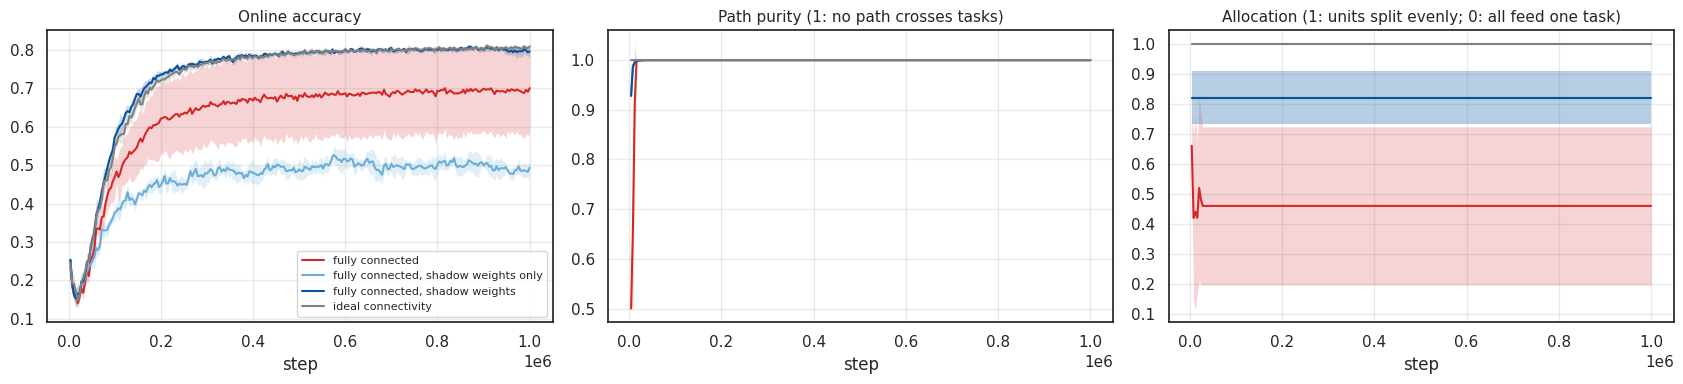

fully connected                        online accuracy 69.41%, allocation 0.46, path purity 1.000
fully connected, shadow weights only   online accuracy 48.96%, allocation 0.82, path purity 1.000
fully connected, shadow weights        online accuracy 80.01%, allocation 0.82, path purity 1.000
ideal connectivity                     online accuracy 80.59%, allocation 1.00, path purity 1.000
H1, shadow weights only vs shadow weights: -31.1 points (± 1.9): held
H2, shadow weights vs ideal connectivity: -0.6 points (± 0.7): held
shadow weights vs fully connected: +10.6 points (± 11.6)


In [7]:
window_ends = np.arange(1, N_WINDOWS + 1) * (NUM_STEPS // N_WINDOWS)
final = slice(-round(N_WINDOWS * FINAL_FRACTION), None)
COLORS = {'fully connected': 'tab:red', 'fully connected, shadow weights only': '#6baed6',
          'fully connected, shadow weights': '#08519c', 'ideal connectivity': 'gray'}


def plot_runs(runs):
    # Accuracy, path purity and allocation over training for each run in `runs` (mean +- 2 SE over seeds).
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    for ax, (key, name) in zip(axes, [('accuracy', 'Online accuracy'),
                                      ('purity', 'Path purity (1: no path crosses tasks)'),
                                      ('allocation', 'Allocation (1: units split evenly; 0: all feed one task)')]):
        for label, res in runs.items():
            mean, sem = res[key].mean(0), res[key].std(0) / np.sqrt(N_SEEDS)
            ax.plot(window_ends, mean, color=COLORS[label], lw=1.5, label=label)
            ax.fill_between(window_ends, mean - 2 * sem, mean + 2 * sem, color=COLORS[label], alpha=0.2, lw=0)
        ax.yaxis.set_major_locator(plt.MultipleLocator(0.1))
        ax.set_xlabel('step')
        ax.set_title(name, fontsize=11)
        ax.grid(alpha=0.4)
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()


def final_mean(res, key='accuracy'):
    return res[key][:, final].mean(1)                        # each seed's mean over the last FINAL_FRACTION


def gap(runs, label, reference):
    return final_mean(runs[label]) - final_mean(runs[reference])     # per seed, on paired seeds


def report(runs, tests):
    # Prints every run's online accuracy, allocation and path purity over the last FINAL_FRACTION of training, then for
    # each test (name, gap, claim) the per-seed gap (mean and 2 SE over seeds) and whether the claim held: 'within'
    # ACCURACY_TOLERANCE of 0 (at most that far below), or more than that 'below' it (no claim: None).
    width = max(map(len, runs))
    for label, res in runs.items():
        print(f'{label:<{width}}   online accuracy {final_mean(res).mean():.2%}, allocation '
              f'{final_mean(res, "allocation").mean():.2f}, path purity {final_mean(res, "purity").mean():.3f}')
    for name, g, claim in tests:
        ok = g.mean() >= -ACCURACY_TOLERANCE if claim == 'within' else g.mean() < -ACCURACY_TOLERANCE
        verdict = '' if claim is None else f': {"held" if ok else "failed"}'
        print(f'{name}: {100 * g.mean():+.1f} points (± {100 * 2 * g.std() / np.sqrt(N_SEEDS):.1f}){verdict}')


runs = {'fully connected': run('fully connected'),
        'fully connected, shadow weights only': run('fully connected', 'shadow weights only'),
        'fully connected, shadow weights': run('fully connected', 'shadow weights'),
        'ideal connectivity': run('ideal connectivity')}
plot_runs(runs)
report(runs, [('H1, shadow weights only vs shadow weights',
               gap(runs, 'fully connected, shadow weights only', 'fully connected, shadow weights'), 'below'),
              ('H2, shadow weights vs ideal connectivity',
               gap(runs, 'fully connected, shadow weights', 'ideal connectivity'), 'within'),
              ('shadow weights vs fully connected', gap(runs, 'fully connected, shadow weights', 'fully connected'),
               None)])

## Results

- **H1 held.** Shadow weights only reach 49.0% online accuracy, −31.1 points (± 1.9, 2 SE over seeds) below shadow
  weights (80.0%): each unit still needs gradients from the other outputs. The earlier version with unit $j$ paired with
  output $j$ failed the same way (50.9% against 80.2%). A likely cause, not tested: a unit that hears from only one
  output, that is, from one label slot, has to relearn its feature every time its task's labels are permuted.
- **H2 held.** Shadow weights reach 80.0%, −0.6 points (± 0.7) from the ideal connectivity (80.6%), and +10.6 points
  (± 11.6) above the plain fully connected network (69.4%).
- **Diagnostics.** Path purity reaches 1 within about 20k steps in every run, so no run mixes the tasks. With either
  version of shadow weights, allocation is 0.82 from the first window on: the split the random pairing gives these
  seeds (13/7 in two seeds, 11/9 in three). The plain fully connected network's allocation is 0.46: it splits its units
  18/2 and 19/1 in two seeds, which end at 58.3% and 50.1%, and 12/8, 12/8 and 16/4 in the other three, which end at
  78.2–80.5%. (Per-seed numbers from a separate run of the same code, with the same means; they are not printed here.)
- So shadow weights do not even out the split, but they stop a task from being starved: they end at 78.3–80.9% in
  every seed, even with a 13/7 split. They do this by exploiting the problem's structure: the pairing gives each task
  units in proportion to its outputs, which is the right split here because the tasks are alike.
- The plain fully connected network does worse on these 5 seeds than over 05's 30 (69.4% against 75.6%, allocation 0.46
  against 0.63), so the gain of shadow weights over it is likely smaller over 30 seeds, where its gap to the ideal
  network is 5.0 points.